<h1>Train — EfficientNet-B0</h1>

Trains and evaluates EfficientNet-B0 using the tuned hyperparameters from `ARCH_HYPERPARAMS["efficientnet_b0"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["efficientnet_b0"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"EfficientNet-B0: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

EfficientNet-B0: micro batch = 16, accumulation steps = 1 (effective batch size ≈ 16, tuned value = 16)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with EfficientNet-B0)
# ---------------------------------------------------------
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# EfficientNet's classifier is nn.Sequential(Dropout, Linear) — swap out
# just the Linear layer for our (optionally deeper) classifier head, same
# as the fc/classifier swaps used for the other architectures.
in_f = model.classifier[1].in_features
model.classifier[1] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[EfficientNet-B0] Epoch   1/100 | LR: 1.72e-04 | train loss 0.9186 acc 0.595 | val loss 0.6364 acc 0.755 *


[EfficientNet-B0] Epoch   2/100 | LR: 1.72e-04 | train loss 0.7203 acc 0.729 | val loss 0.5451 acc 0.782 *


[EfficientNet-B0] Epoch   3/100 | LR: 1.72e-04 | train loss 0.6596 acc 0.747 | val loss 0.5496 acc 0.777


[EfficientNet-B0] Epoch   4/100 | LR: 1.72e-04 | train loss 0.6560 acc 0.748 | val loss 0.5263 acc 0.764 *


[EfficientNet-B0] Epoch   5/100 | LR: 1.72e-04 | train loss 0.5890 acc 0.772 | val loss 0.6047 acc 0.725


...

[EfficientNet-B0] Epoch  18/100 | LR: 1.72e-04 | train loss 0.2567 acc 0.898 | val loss 0.6388 acc 0.803


[EfficientNet-B0] Epoch  19/100 | LR: 1.72e-04 | train loss 0.3120 acc 0.875 | val loss 0.6859 acc 0.777


[EfficientNet-B0] Epoch  20/100 | LR: 1.72e-04 | train loss 0.2660 acc 0.904 | val loss 0.7989 acc 0.721


[EfficientNet-B0] Epoch  21/100 | LR: 1.72e-04 | train loss 0.2792 acc 0.894 | val loss 0.6557 acc 0.795


[EfficientNet-B0] Epoch  22/100 | LR: 1.72e-05 | train loss 0.2327 acc 0.926 | val loss 0.6537 acc 0.773

[EfficientNet-B0] No val loss improvement for 10 epochs — stopping early at epoch 22.

[EfficientNet-B0] Restored best checkpoint (val loss = 0.5065)


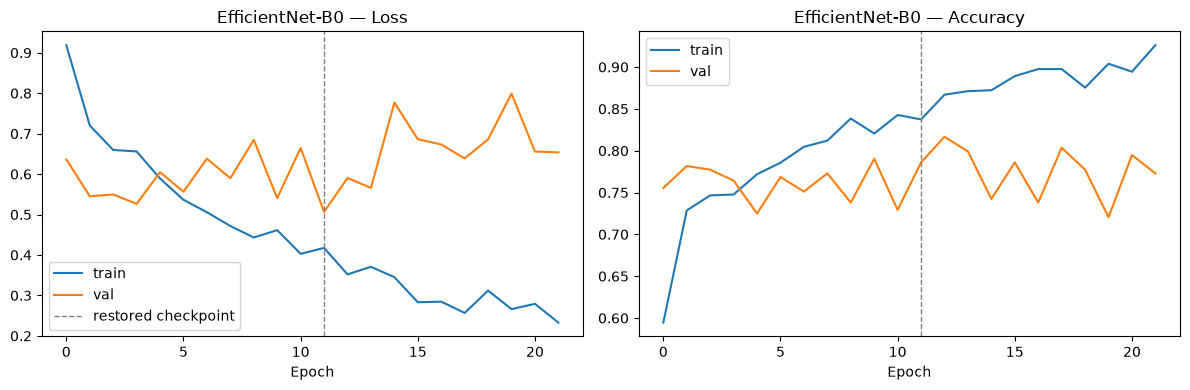

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "EfficientNet-B0", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "EfficientNet-B0")

## Evaluate on the test set

[EfficientNet-B0] Test accuracy: 0.857


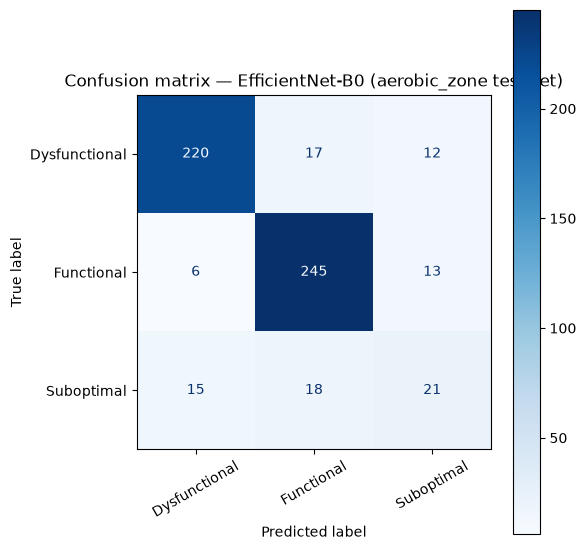

               precision    recall  f1-score   support

Dysfunctional      0.913     0.884     0.898       249
   Functional      0.875     0.928     0.901       264
   Suboptimal      0.457     0.389     0.420        54

     accuracy                          0.857       567
    macro avg      0.748     0.733     0.740       567
 weighted avg      0.852     0.857     0.854       567



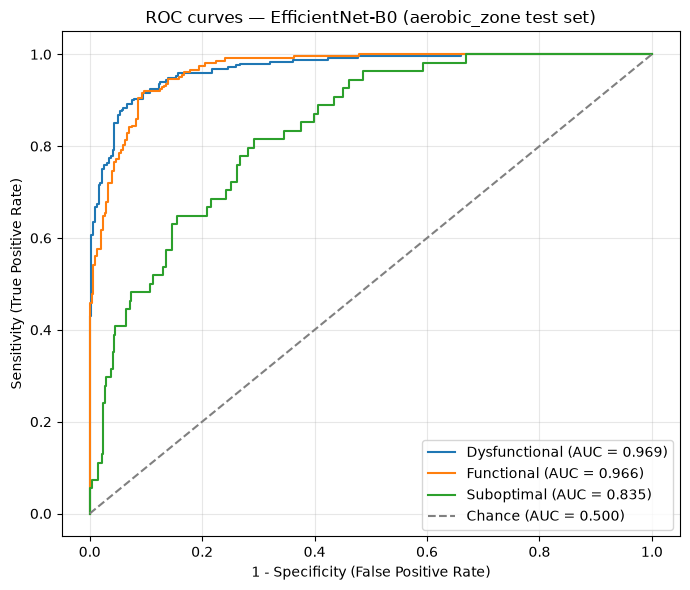

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.969
  Functional     : 0.966
  Suboptimal     : 0.835

Mean AUC (over 3/3 classes with test examples): 0.924


(np.float64(0.8571428571428571),
 {'Dysfunctional': 0.9694248692884746,
  'Functional': 0.9664716471647165,
  'Suboptimal': 0.8347411739224604})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "EfficientNet-B0", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("EfficientNet-B0", "efficientnet_b0")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_efficientnet_b0_chronological.pkl


Saved model weights to ../models/pad/aerobic_zone_efficientnet_b0_cnn.pt
